# LLM Performance Analysis on Unseen Data

This notebook analyzes LLM model outputs on **unseen/unlabeled data** for conspiracy classification and span extraction tasks.

Since there is no human ground truth for unseen data, this analysis focuses on:
- Inter-model agreement metrics (Cohen's Kappa for primary labels)
- Prediction distribution analysis
- Span extraction patterns comparison
- Model consensus analysis

## Models Analyzed:
1. **Llama-3-8B-Instruct Few-Shot** (`8b_few`)
2. **Llama-3-8B-Instruct Few-Shot + Frames** (`8b_frame`)
3. **Llama-3.3-70B-Instruct Few-Shot** (`70b_few`)
4. **Llama-3.3-70B-Instruct Few-Shot + Frames** (`70b_frame`)

## Output:
- Inter-model agreement tables (pairwise Kappa)
- Prediction distribution statistics
- Span extraction comparison metrics
- Visualizations for model comparison
- CSV and LaTeX exports for paper inclusion


## 1. Setup & Imports


In [ ]:
# Setup & Imports
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import cohen_kappa_score
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_theme(context="notebook", style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Set paths
BASE = Path('/home/ashrafs/projects/Conspiracy-Proj')
DATA = BASE / 'Data'
OUT = BASE / 'outputs'
PUB_TABLES = BASE / 'publication' / 'tables'
PUB_FIGURES = BASE / 'publication' / 'figures'
PUB_TABLES.mkdir(exist_ok=True, parents=True)
PUB_FIGURES.mkdir(exist_ok=True, parents=True)

print("✓ Setup complete!")
print(f"Data directory: {DATA}")
print(f"Output directory: {OUT}")
print(f"Tables directory: {PUB_TABLES}")
print(f"Figures directory: {PUB_FIGURES}")


✓ Setup complete!
Data directory: /home/ashrafs/projects/Conspiracy-Proj/Data
Output directory: /home/ashrafs/projects/Conspiracy-Proj/outputs
Tables directory: /home/ashrafs/projects/Conspiracy-Proj/publication/tables
Figures directory: /home/ashrafs/projects/Conspiracy-Proj/publication/figures


## 2. Load Model Outputs


In [ ]:
# Model file mappings
MODEL_FILES = {
    '8b_few': {
        'classifications': OUT / 'llama8b-fewshot_un-labelled_all_classifications.csv',
        'spans': OUT / 'llama8b-fewshot_un-labelled_all_span_annotations.csv',
        'name': '8B Few-Shot'
    },
    '8b_frame': {
        'classifications': OUT / 'llama8b-fewshot-frames_un-labelled_all_classifications.csv',
        'spans': OUT / 'llama8b-fewshot-frames_un-labelled_all_span_annotations.csv',
        'name': '8B Few-Shot+Frames'
    },
    '70b_few': {
        'classifications': OUT / 'llama-3.3-70B-fewshot_un-labelled_all_classifications.csv',
        'spans': OUT / 'llama-3.3-70B-fewshot_un-labelled_all_span_annotations.csv',
        'name': '70B Few-Shot'
    },
    '70b_frame': {
        'classifications': OUT / 'llama-3.3-70B-fewshot-frames_un-labelled_all_classifications.csv',
        'spans': OUT / 'llama-3.3-70B-fewshot-frames_un-labelled_all_span_annotations.csv',
        'name': '70B Few-Shot+Frames'
    }
}

# Boolean parsing function
BOOL_MAP = {'true': True, 'false': False, 'yes': True, 'no': False, 'y': True, 'n': False, '1': True, '0': False, True: True, False: False}

def parse_bool(s: pd.Series) -> pd.Series:
    """Parse boolean values from various formats."""
    if s.dtype == 'bool':
        return s
    v = s.astype(str).str.strip().str.lower().map(BOOL_MAP)
    unmapped = v.isna()
    if unmapped.any():
        num = pd.to_numeric(s[unmapped], errors='coerce')
        v.loc[unmapped & num.notna()] = (num[num.notna()] > 0).astype(bool)
    return v.fillna(False).astype(bool)

# Load all model outputs
print("Loading model outputs for unseen data...")
print("=" * 80)

model_classifications = {}
model_spans = {}

for model_code, file_info in MODEL_FILES.items():
    # Load classifications
    if file_info['classifications'].exists():
        df_class = pd.read_csv(file_info['classifications'])
        df_class['conspiracy_bool'] = parse_bool(df_class['conspiracy'])
        model_classifications[model_code] = df_class
        print(f"✓ {file_info['name']}: {len(df_class):,} classifications")
    else:
        print(f"✗ {file_info['name']}: Classification file not found")
    
    # Load spans
    if file_info['spans'].exists():
        df_spans = pd.read_csv(file_info['spans'])
        model_spans[model_code] = df_spans
        print(f"  → {len(df_spans):,} span annotations")
    else:
        print(f"  → Span file not found")

print("=" * 80)
print(f"\nTotal models loaded: {len(model_classifications)}")


Loading model outputs for unseen data...
✓ 8B Few-Shot: 2,660 classifications
  → 2,660 span annotations
✓ 8B Few-Shot+Frames: 2,660 classifications
  → 2,660 span annotations
✓ 70B Few-Shot: 2,660 classifications
  → 2,660 span annotations
✓ 70B Few-Shot+Frames: 2,660 classifications
  → 2,660 span annotations

Total models loaded: 4


## 3. Primary Label Analysis: Inter-Model Agreement


In [ ]:
def calculate_pairwise_kappa_unseen(model1_code, model2_code, model_classifications):
    """Calculate Cohen's Kappa between two models on unseen data."""
    if model1_code not in model_classifications or model2_code not in model_classifications:
        return None, 0
    
    m1 = model_classifications[model1_code].copy()
    m2 = model_classifications[model2_code].copy()
    
    # Merge on text_id
    merged = m1.merge(m2, on='text_id', suffixes=('_1', '_2'), how='inner')
    
    if len(merged) == 0:
        return None, 0
    
    # Filter out rows where either model has NaN
    merged = merged.dropna(subset=['conspiracy_bool_1', 'conspiracy_bool_2'])
    
    if len(merged) == 0:
        return None, 0
    
    # Ensure boolean type
    merged['conspiracy_bool_1'] = merged['conspiracy_bool_1'].fillna(False).astype(bool)
    merged['conspiracy_bool_2'] = merged['conspiracy_bool_2'].fillna(False).astype(bool)
    
    y1 = merged['conspiracy_bool_1'].astype(int).values
    y2 = merged['conspiracy_bool_2'].astype(int).values
    
    # Calculate Cohen's Kappa
    try:
        kappa = cohen_kappa_score(y1, y2)
        return kappa, len(merged)
    except:
        return None, len(merged)

# Calculate pairwise agreement for all model pairs
print("Calculating pairwise Cohen's Kappa for unseen data...")
print("=" * 80)

pairwise_results = []
model_codes = list(model_classifications.keys())

for model1, model2 in combinations(model_codes, 2):
    kappa, n_texts = calculate_pairwise_kappa_unseen(model1, model2, model_classifications)
    if kappa is not None:
        pairwise_results.append({
            'Model_1': MODEL_FILES[model1]['name'],
            'Model_2': MODEL_FILES[model2]['name'],
            'Model_1_Code': model1,
            'Model_2_Code': model2,
            'Kappa': kappa,
            'N_Texts': n_texts
        })

pairwise_df = pd.DataFrame(pairwise_results)

if len(pairwise_df) > 0:
    pairwise_df = pairwise_df.sort_values('Kappa', ascending=False)
    print("\nPairwise Inter-Model Agreement (Cohen's Kappa):")
    print(pairwise_df[['Model_1', 'Model_2', 'Kappa', 'N_Texts']].to_string(index=False))
    print(f"\nMean Kappa: {pairwise_df['Kappa'].mean():.4f} (SD={pairwise_df['Kappa'].std():.4f})")
    print(f"Min Kappa: {pairwise_df['Kappa'].min():.4f}")
    print(f"Max Kappa: {pairwise_df['Kappa'].max():.4f}")
else:
    print("No pairwise agreements calculated.")


Calculating pairwise Cohen's Kappa for unseen data...

Pairwise Inter-Model Agreement (Cohen's Kappa):
           Model_1             Model_2    Kappa  N_Texts
      70B Few-Shot 70B Few-Shot+Frames 0.960475     2660
       8B Few-Shot  8B Few-Shot+Frames 0.921918     2660
       8B Few-Shot        70B Few-Shot 0.662066     2660
       8B Few-Shot 70B Few-Shot+Frames 0.660243     2660
8B Few-Shot+Frames 70B Few-Shot+Frames 0.659659     2660
8B Few-Shot+Frames        70B Few-Shot 0.656643     2660

Mean Kappa: 0.7535 (SD=0.1459)
Min Kappa: 0.6566
Max Kappa: 0.9605


## 4. Prediction Distribution Analysis


In [ ]:
# Calculate prediction distributions for each model
print("Prediction Distribution Analysis")
print("=" * 80)

distribution_results = []

for model_code, df in model_classifications.items():
    total = len(df)
    conspiratorial = df['conspiracy_bool'].sum()
    non_conspiratorial = total - conspiratorial
    conspiratorial_pct = (conspiratorial / total * 100) if total > 0 else 0
    
    distribution_results.append({
        'Model': MODEL_FILES[model_code]['name'],
        'Model_Code': model_code,
        'Total': total,
        'Conspiratorial': conspiratorial,
        'Non-Conspiratorial': non_conspiratorial,
        'Conspiratorial_%': conspiratorial_pct
    })
    
    print(f"\n{MODEL_FILES[model_code]['name']}:")
    print(f"  Total texts: {total:,}")
    print(f"  Conspiratorial: {conspiratorial:,} ({conspiratorial_pct:.1f}%)")
    print(f"  Non-conspiratorial: {non_conspiratorial:,} ({100-conspiratorial_pct:.1f}%)")

distribution_df = pd.DataFrame(distribution_results)
print("\n" + "=" * 80)


Prediction Distribution Analysis

8B Few-Shot:
  Total texts: 2,660
  Conspiratorial: 1,191 (44.8%)
  Non-conspiratorial: 1,469 (55.2%)

8B Few-Shot+Frames:
  Total texts: 2,660
  Conspiratorial: 1,226 (46.1%)
  Non-conspiratorial: 1,434 (53.9%)

70B Few-Shot:
  Total texts: 2,660
  Conspiratorial: 1,119 (42.1%)
  Non-conspiratorial: 1,541 (57.9%)

70B Few-Shot+Frames:
  Total texts: 2,660
  Conspiratorial: 1,080 (40.6%)
  Non-conspiratorial: 1,580 (59.4%)



## 5. Span Extraction Analysis


In [ ]:
# Analyze span extraction patterns
print("Span Extraction Analysis")
print("=" * 80)

span_columns = ['plan', 'secret', 'in-group', 'out-group', 'call-to-action']
span_results = []

for model_code, df_spans in model_spans.items():
    total_texts = df_spans['text_id'].nunique()
    
    span_stats = {'Model': MODEL_FILES[model_code]['name'], 'Model_Code': model_code, 'Total_Texts': total_texts}
    
    for span_type in span_columns:
        if span_type in df_spans.columns:
            # Count texts with non-empty spans for this type
            has_span = df_spans[span_type].notna() & (df_spans[span_type].astype(str).str.strip() != '')
            count = has_span.sum()
            pct = (count / total_texts * 100) if total_texts > 0 else 0
            
            span_stats[f'{span_type}_count'] = count
            span_stats[f'{span_type}_pct'] = pct
        else:
            span_stats[f'{span_type}_count'] = 0
            span_stats[f'{span_type}_pct'] = 0
    
    span_results.append(span_stats)
    
    print(f"\n{MODEL_FILES[model_code]['name']}:")
    print(f"  Total texts: {total_texts:,}")
    for span_type in span_columns:
        count = span_stats.get(f'{span_type}_count', 0)
        pct = span_stats.get(f'{span_type}_pct', 0)
        print(f"  {span_type}: {count:,} ({pct:.1f}%)")

span_df = pd.DataFrame(span_results)
print("\n" + "=" * 80)


Span Extraction Analysis

8B Few-Shot:
  Total texts: 2,660
  plan: 1,070 (40.2%)
  secret: 1,108 (41.7%)
  in-group: 184 (6.9%)
  out-group: 844 (31.7%)
  call-to-action: 113 (4.2%)

8B Few-Shot+Frames:
  Total texts: 2,660
  plan: 1,133 (42.6%)
  secret: 1,055 (39.7%)
  in-group: 239 (9.0%)
  out-group: 848 (31.9%)
  call-to-action: 102 (3.8%)

70B Few-Shot:
  Total texts: 2,660
  plan: 1,110 (41.7%)
  secret: 582 (21.9%)
  in-group: 435 (16.4%)
  out-group: 897 (33.7%)
  call-to-action: 540 (20.3%)

70B Few-Shot+Frames:
  Total texts: 2,660
  plan: 1,076 (40.5%)
  secret: 587 (22.1%)
  in-group: 486 (18.3%)
  out-group: 874 (32.9%)
  call-to-action: 517 (19.4%)



## 6. Model Consensus Analysis


In [ ]:
# Analyze consensus across models (how many models agree on each prediction)
print("Model Consensus Analysis")
print("=" * 80)

# Get all unique text_ids across all models
all_text_ids = set()
for df in model_classifications.values():
    all_text_ids.update(df['text_id'].unique())

print(f"Total unique texts across all models: {len(all_text_ids):,}")

# For each text, count how many models predict conspiracy
consensus_data = [] cx  

for text_id in sorted(all_text_ids):
    predictions = {}
    for model_code, df in model_classifications.items():
        text_rows = df[df['text_id'] == text_id]
        if len(text_rows) > 0:
            predictions[model_code] = text_rows.iloc[0]['conspiracy_bool']
    
    if len(predictions) > 0:
        conspiracy_count = sum(1 for p in predictions.values() if p)
        total_models = len(predictions)
        consensus_data.append({
            'text_id': text_id,
            'conspiracy_count': conspiracy_count,
            'total_models': total_models,
            'consensus': conspiracy_count == total_models,  # All agree conspiracy
            'unanimous_no': conspiracy_count == 0,  # All agree non-conspiracy
            'disagreement': conspiracy_count > 0 and conspiracy_count < total_models  # Some disagreement
        })

consensus_df = pd.DataFrame(consensus_data)

if len(consensus_df) > 0:
    total_texts = len(consensus_df)
    unanimous_yes = consensus_df['consensus'].sum()
    unanimous_no = consensus_df['unanimous_no'].sum()
    disagreement = consensus_df['disagreement'].sum()
    
    print(f"\nConsensus Statistics:")
    print(f"  Unanimous 'Yes' (all models predict conspiracy): {unanimous_yes:,} ({unanimous_yes/total_texts*100:.1f}%)")
    print(f"  Unanimous 'No' (all models predict non-conspiracy): {unanimous_no:,} ({unanimous_no/total_texts*100:.1f}%)")
    print(f"  Disagreement (models disagree): {disagreement:,} ({disagreement/total_texts*100:.1f}%)")
    
    # Distribution of agreement levels
    print(f"\nAgreement Distribution:")
    agreement_dist = consensus_df['conspiracy_count'].value_counts().sort_index()
    for count, freq in agreement_dist.items():
        pct = (freq / total_texts * 100)
        print(f"  {count}/{len(model_codes)} models predict conspiracy: {freq:,} texts ({pct:.1f}%)")

print("\n" + "=" * 80)


Model Consensus Analysis
Total unique texts across all models: 2,660

Consensus Statistics:
  Unanimous 'Yes' (all models predict conspiracy): 899 (33.8%)
  Unanimous 'No' (all models predict non-conspiracy): 1,240 (46.6%)
  Disagreement (models disagree): 521 (19.6%)

Agreement Distribution:
  0/4 models predict conspiracy: 1,240 texts (46.6%)
  1/4 models predict conspiracy: 85 texts (3.2%)
  2/4 models predict conspiracy: 373 texts (14.0%)
  3/4 models predict conspiracy: 63 texts (2.4%)
  4/4 models predict conspiracy: 899 texts (33.8%)



## 7. Create Visualizations


✓ Saved heatmap: /home/ashrafs/projects/Conspiracy-Proj/publication/figures/llm_unseen_inter_model_agreement_heatmap.png


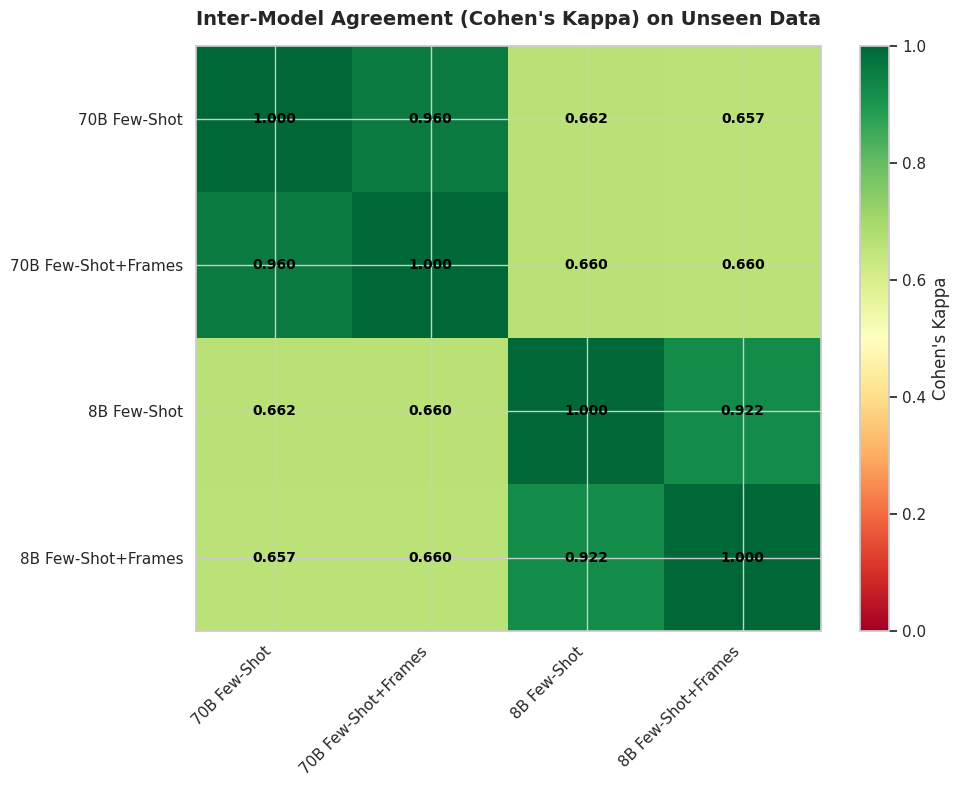

In [ ]:
# Visualization 1: Pairwise Kappa Agreement Heatmap
if len(pairwise_df) > 0:
    # Create a matrix for heatmap
    models = sorted(set(pairwise_df['Model_1'].unique()) | set(pairwise_df['Model_2'].unique()))
    kappa_matrix = np.full((len(models), len(models)), np.nan)
    
    model_to_idx = {model: i for i, model in enumerate(models)}
    
    for _, row in pairwise_df.iterrows():
        i = model_to_idx[row['Model_1']]
        j = model_to_idx[row['Model_2']]
        kappa_matrix[i, j] = row['Kappa']
        kappa_matrix[j, i] = row['Kappa']  # Symmetric
    
    # Diagonal is perfect agreement (kappa = 1.0)
    np.fill_diagonal(kappa_matrix, 1.0)
    
    fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    im = ax.imshow(kappa_matrix, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
    
    # Set labels
    ax.set_xticks(np.arange(len(models)))
    ax.set_yticks(np.arange(len(models)))
    ax.set_xticklabels(models, rotation=45, ha='right')
    ax.set_yticklabels(models)
    
    # Add text annotations
    for i in range(len(models)):
        for j in range(len(models)):
            if not np.isnan(kappa_matrix[i, j]):
                text = ax.text(j, i, f'{kappa_matrix[i, j]:.3f}',
                             ha="center", va="center", color="black", fontweight='bold', fontsize=10)
    
    ax.set_title("Inter-Model Agreement (Cohen's Kappa) on Unseen Data", fontweight='bold', fontsize=14, pad=15)
    plt.colorbar(im, ax=ax, label="Cohen's Kappa")
    plt.tight_layout()
    
    fig_path = PUB_FIGURES / 'llm_unseen_inter_model_agreement_heatmap.png'
    plt.savefig(fig_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"✓ Saved heatmap: {fig_path}")
    plt.show()


✓ Saved distribution plot: /home/ashrafs/projects/Conspiracy-Proj/publication/figures/llm_unseen_prediction_distribution.png


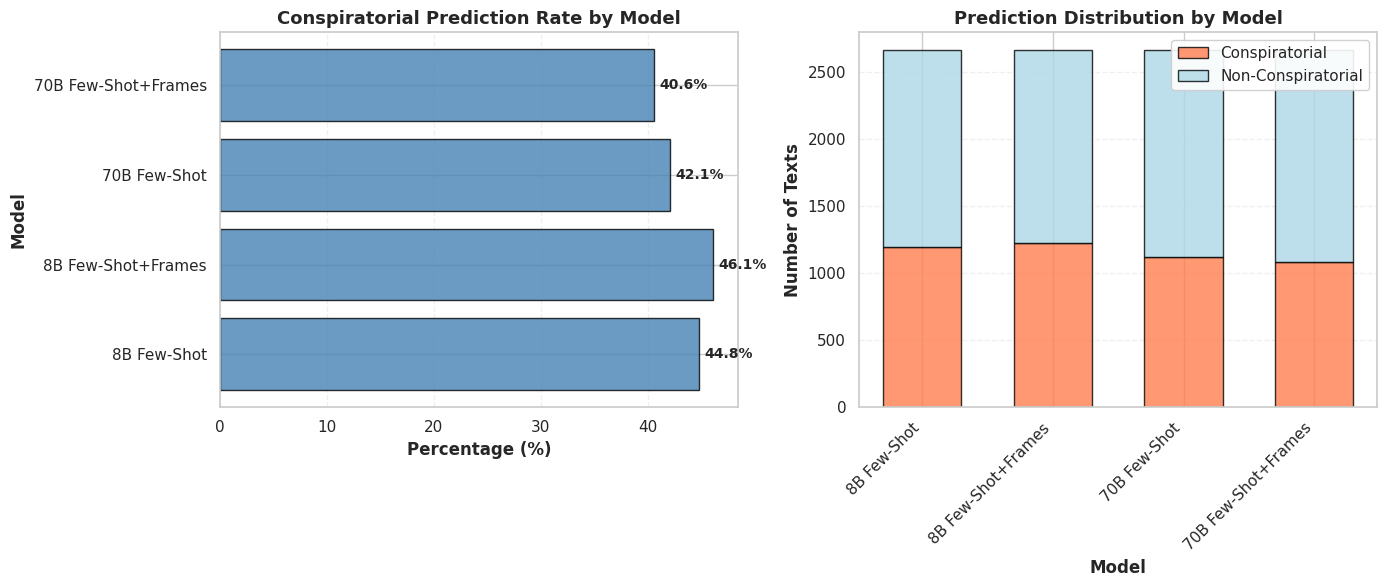

In [ ]:
# Visualization 2: Prediction Distribution Comparison
if len(distribution_df) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Bar chart: Conspiratorial percentage
    ax1 = axes[0]
    bars = ax1.barh(distribution_df['Model'], distribution_df['Conspiratorial_%'], 
                    color='steelblue', alpha=0.8, edgecolor='black')
    ax1.set_xlabel('Percentage (%)', fontweight='bold', fontsize=12)
    ax1.set_ylabel('Model', fontweight='bold', fontsize=12)
    ax1.set_title('Conspiratorial Prediction Rate by Model', fontweight='bold', fontsize=13)
    ax1.grid(axis='x', alpha=0.3, linestyle='--')
    
    for i, bar in enumerate(bars):
        width = bar.get_width()
        ax1.text(width + 0.5, bar.get_y() + bar.get_height()/2, 
                f'{width:.1f}%', va='center', fontsize=10, fontweight='bold')
    
    # Stacked bar chart: Count distribution
    ax2 = axes[1]
    x = np.arange(len(distribution_df))
    width = 0.6
    
    bars1 = ax2.bar(x, distribution_df['Conspiratorial'], width, label='Conspiratorial', 
                    color='coral', alpha=0.8, edgecolor='black')
    bars2 = ax2.bar(x, distribution_df['Non-Conspiratorial'], width, 
                    bottom=distribution_df['Conspiratorial'], label='Non-Conspiratorial',
                    color='lightblue', alpha=0.8, edgecolor='black')
    
    ax2.set_xlabel('Model', fontweight='bold', fontsize=12)
    ax2.set_ylabel('Number of Texts', fontweight='bold', fontsize=12)
    ax2.set_title('Prediction Distribution by Model', fontweight='bold', fontsize=13)
    ax2.set_xticks(x)
    ax2.set_xticklabels(distribution_df['Model'], rotation=45, ha='right')
    ax2.legend(loc='upper right', framealpha=0.9)
    ax2.grid(axis='y', alpha=0.3, linestyle='--')
    
    plt.tight_layout()
    
    fig_path = PUB_FIGURES / 'llm_unseen_prediction_distribution.png'
    plt.savefig(fig_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"✓ Saved distribution plot: {fig_path}")
    plt.show()


✓ Saved span comparison: /home/ashrafs/projects/Conspiracy-Proj/publication/figures/llm_unseen_span_extraction_comparison.png


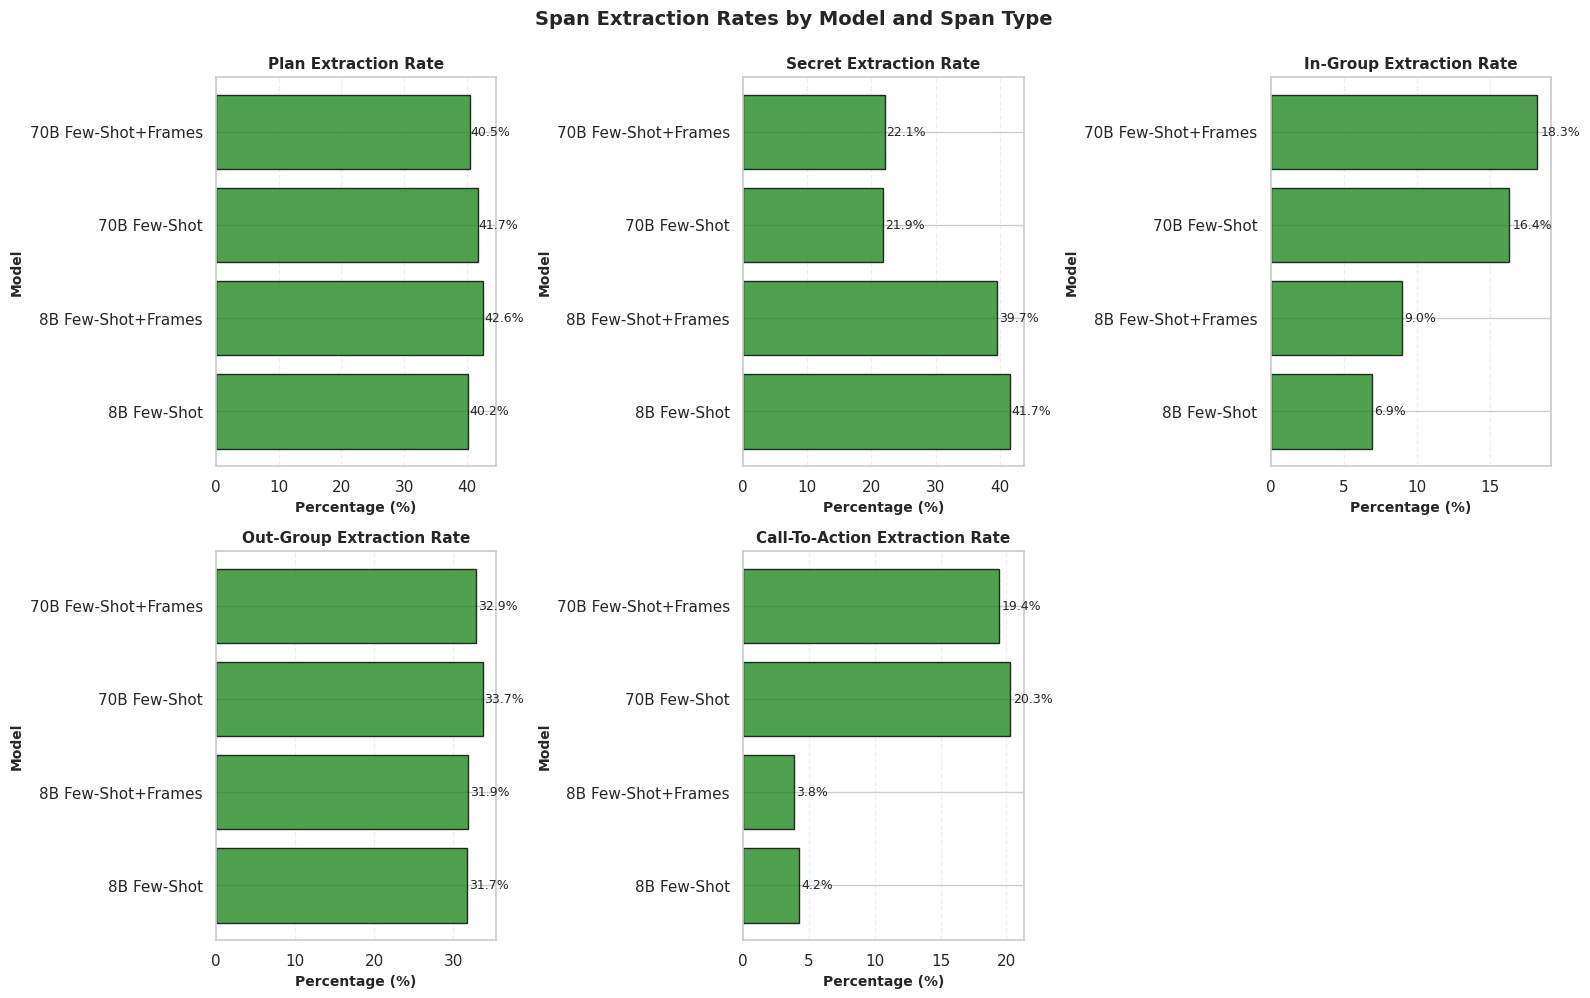

In [ ]:
# Visualization 3: Span Extraction Comparison
if len(span_df) > 0:
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.flatten()
    
    span_types = ['plan', 'secret', 'in-group', 'out-group', 'call-to-action']
    
    for idx, span_type in enumerate(span_types):
        if idx < len(axes):
            ax = axes[idx]
            col_name = f'{span_type}_pct'
            
            if col_name in span_df.columns:
                bars = ax.barh(span_df['Model'], span_df[col_name], 
                             color='forestgreen', alpha=0.8, edgecolor='black')
                ax.set_xlabel('Percentage (%)', fontweight='bold', fontsize=10)
                ax.set_ylabel('Model', fontweight='bold', fontsize=10)
                ax.set_title(f'{span_type.title()} Extraction Rate', fontweight='bold', fontsize=11)
                ax.grid(axis='x', alpha=0.3, linestyle='--')
                
                for bar in bars:
                    width = bar.get_width()
                    if width > 0:
                        ax.text(width + 0.2, bar.get_y() + bar.get_height()/2, 
                               f'{width:.1f}%', va='center', fontsize=9)
    
    # Hide unused subplot
    axes[5].axis('off')
    
    plt.suptitle('Span Extraction Rates by Model and Span Type', fontweight='bold', fontsize=14, y=0.995)
    plt.tight_layout()
    
    fig_path = PUB_FIGURES / 'llm_unseen_span_extraction_comparison.png'
    plt.savefig(fig_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"✓ Saved span comparison: {fig_path}")
    plt.show()


## 8. Export Results


In [ ]:
# Export Pairwise Kappa Agreement
if len(pairwise_df) > 0:
    csv_path = PUB_TABLES / 'llm_unseen_pairwise_kappa.csv'
    export_df = pairwise_df[['Model_1', 'Model_2', 'Kappa', 'N_Texts']].copy()
    export_df.to_csv(csv_path, index=False, float_format='%.4f')
    print(f"✓ Exported CSV: {csv_path}")
    
    # Export LaTeX table
    latex_path = PUB_TABLES / 'llm_unseen_pairwise_kappa.tex'
    latex_str = "\\begin{table}[t]\n"
    latex_str += "\\centering\n"
    latex_str += "\\caption{Inter-Model Agreement (Cohen's Kappa) on Unseen Data}\n"
    latex_str += "\\label{tab:llm_unseen_pairwise_kappa}\n"
    latex_str += "\\begin{tabular}{lcc}\n"
    latex_str += "\\toprule\n"
    latex_str += "Model 1 & Model 2 & Kappa \\\\\n"
    latex_str += "\\midrule\n"
    
    for _, row in pairwise_df.iterrows():
        model1 = row['Model_1'].replace('_', '\\_')
        model2 = row['Model_2'].replace('_', '\\_')
        latex_str += f"{model1} & {model2} & {row['Kappa']:.4f} \\\\\n"
    
    latex_str += "\\bottomrule\n"
    latex_str += "\\end{tabular}\n"
    latex_str += "\\end{table}\n"
    
    with open(latex_path, 'w') as f:
        f.write(latex_str)
    print(f"✓ Exported LaTeX table: {latex_path}")
else:
    print("No pairwise agreement data to export.")


✓ Exported CSV: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/llm_unseen_pairwise_kappa.csv
✓ Exported LaTeX table: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/llm_unseen_pairwise_kappa.tex


In [ ]:
# Export Prediction Distribution
if len(distribution_df) > 0:
    csv_path = PUB_TABLES / 'llm_unseen_prediction_distribution.csv'
    export_df = distribution_df[['Model', 'Total', 'Conspiratorial', 'Non-Conspiratorial', 'Conspiratorial_%']].copy()
    export_df.to_csv(csv_path, index=False, float_format='%.2f')
    print(f"✓ Exported CSV: {csv_path}")
    
    # Export LaTeX table
    latex_path = PUB_TABLES / 'llm_unseen_prediction_distribution.tex'
    latex_str = "\\begin{table}[t]\n"
    latex_str += "\\centering\n"
    latex_str += "\\caption{Prediction Distribution on Unseen Data}\n"
    latex_str += "\\label{tab:llm_unseen_distribution}\n"
    latex_str += "\\begin{tabular}{lrrrr}\n"
    latex_str += "\\toprule\n"
    latex_str += "Model & Total & Conspiratorial & Non-Conspiratorial & Conspiratorial (\\%) \\\\\n"
    latex_str += "\\midrule\n"
    
    for _, row in distribution_df.iterrows():
        model = row['Model'].replace('_', '\\_')
        latex_str += f"{model} & {int(row['Total']):,} & {int(row['Conspiratorial']):,} & {int(row['Non-Conspiratorial']):,} & {row['Conspiratorial_%']:.1f} \\\\\n"
    
    latex_str += "\\bottomrule\n"
    latex_str += "\\end{tabular}\n"
    latex_str += "\\end{table}\n"
    
    with open(latex_path, 'w') as f:
        f.write(latex_str)
    print(f"✓ Exported LaTeX table: {latex_path}")
else:
    print("No distribution data to export.")


✓ Exported CSV: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/llm_unseen_prediction_distribution.csv
✓ Exported LaTeX table: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/llm_unseen_prediction_distribution.tex


In [ ]:
# Export Span Extraction Summary
if len(span_df) > 0:
    csv_path = PUB_TABLES / 'llm_unseen_span_extraction.csv'
    
    # Create summary table
    summary_cols = ['Model', 'Total_Texts']
    for span_type in ['plan', 'secret', 'in-group', 'out-group', 'call-to-action']:
        summary_cols.extend([f'{span_type}_count', f'{span_type}_pct'])
    
    export_df = span_df[summary_cols].copy()
    export_df.to_csv(csv_path, index=False, float_format='%.2f')
    print(f"✓ Exported CSV: {csv_path}")
    
    print("\n" + "=" * 80)
    print("Export Summary:")
    print(f"  - Pairwise Kappa: {PUB_TABLES / 'llm_unseen_pairwise_kappa.csv'}")
    print(f"  - Prediction Distribution: {PUB_TABLES / 'llm_unseen_prediction_distribution.csv'}")
    print(f"  - Span Extraction: {PUB_TABLES / 'llm_unseen_span_extraction.csv'}")
    print("=" * 80)
else:
    print("No span data to export.")


✓ Exported CSV: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/llm_unseen_span_extraction.csv

Export Summary:
  - Pairwise Kappa: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/llm_unseen_pairwise_kappa.csv
  - Prediction Distribution: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/llm_unseen_prediction_distribution.csv
  - Span Extraction: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/llm_unseen_span_extraction.csv
